<a href="https://colab.research.google.com/github/Nashwath1901/SRM/blob/main/hospital_booking_%26_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder,StandardScaler,FunctionTransformer
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score,classification_report


In [2]:
df = pd.read_csv('/content/healthcare_noshows.csv')

In [3]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,Showed_up,Date.diff
0,2.987250e+13,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,False,True,False,False,False,False,True,0.0
1,5.589978e+14,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,False,False,False,False,False,True,0.0
2,4.262962e+12,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,False,False,False,False,False,False,True,0.0
3,8.679512e+11,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,False,False,False,True,0.0
4,8.841186e+12,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,True,True,False,False,False,True,0.0


In [4]:
df.shape

(38567, 15)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38567 entries, 0 to 38566
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PatientId       38567 non-null  float64
 1   AppointmentID   38567 non-null  int64  
 2   Gender          38567 non-null  object 
 3   ScheduledDay    38567 non-null  object 
 4   AppointmentDay  38567 non-null  object 
 5   Age             38567 non-null  int64  
 6   Neighbourhood   38567 non-null  object 
 7   Scholarship     38567 non-null  bool   
 8   Hipertension    38567 non-null  bool   
 9   Diabetes        38566 non-null  object 
 10  Alcoholism      38566 non-null  object 
 11  Handcap         38566 non-null  object 
 12  SMS_received    38566 non-null  object 
 13  Showed_up       38566 non-null  object 
 14  Date.diff       38566 non-null  float64
dtypes: bool(2), float64(2), int64(2), object(9)
memory usage: 3.9+ MB


In [6]:
df.isnull().sum()

,0
PatientId,0
AppointmentID,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,1


In [7]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

In [8]:
df['S_year'] = df['ScheduledDay'].dt.year
df['S_month'] = df['ScheduledDay'].dt.month
df['S_day_date'] = df['ScheduledDay'].dt.day
df['S_day_of_week'] = df['ScheduledDay'].dt.day_name()

df['A_year'] = df['AppointmentDay'].dt.year
df['A_month'] = df['AppointmentDay'].dt.month
df['A_day_date'] = df['AppointmentDay'].dt.day
df['A_day_of_week'] = df['AppointmentDay'].dt.day_name()

In [9]:
df.head(20)

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,...,Showed_up,Date.diff,S_year,S_month,S_day_date,S_day_of_week,A_year,A_month,A_day_date,A_day_of_week
0,2.987250e+13,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,False,True,False,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
1,5.589978e+14,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,False,False,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
2,4.262962e+12,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,False,False,False,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
3,8.679512e+11,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
4,8.841186e+12,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,True,True,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
5,9.598513e+13,5626772,F,2016-04-27,2016-04-29,76,REPÚBLICA,False,True,False,...,True,2.0,2016,4,27,Wednesday,2016,4,29,Friday
6,7.336882e+14,5630279,F,2016-04-27,2016-04-29,23,GOIABEIRAS,False,False,False,...,False,2.0,2016,4,27,Wednesday,2016,4,29,Friday
7,3.449833e+12,5630575,F,2016-04-27,2016-04-29,39,GOIABEIRAS,False,False,False,...,False,2.0,2016,4,27,Wednesday,2016,4,29,Friday
8,5.639473e+13,5638447,F,2016-04-29,2016-04-29,21,ANDORINHAS,False,False,False,...,True,0.0,2016,4,29,Friday,2016,4,29,Friday
9,7.812456e+13,5629123,F,2016-04-27,2016-04-29,19,CONQUISTA,False,False,False,...,True,2.0,2016,4,27,Wednesday,2016,4,29,Friday


In [10]:
df['Year_difference'] = df['A_year']- df['S_year']
df['month_difference'] = df['A_month']- df['S_month']
df['day_difference'] = df['A_day_date']- df['S_day_date']

df['Year_difference']=df['Year_difference'].abs()
df['month_difference']=df['month_difference'].abs()
df['day_difference']=df['day_difference'].abs()

In [11]:
df['A_month'] = df['AppointmentDay'].dt.month_name()
df['S_month'] = df['ScheduledDay'].dt.month_name()

In [12]:
df.head(20)

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,...,S_month,S_day_date,S_day_of_week,A_year,A_month,A_day_date,A_day_of_week,Year_difference,month_difference,day_difference
0,2.987250e+13,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,False,True,False,...,April,29,Friday,2016,April,29,Friday,0,0,0
1,5.589978e+14,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,False,False,...,April,29,Friday,2016,April,29,Friday,0,0,0
2,4.262962e+12,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,False,False,False,...,April,29,Friday,2016,April,29,Friday,0,0,0
3,8.679512e+11,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,...,April,29,Friday,2016,April,29,Friday,0,0,0
4,8.841186e+12,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,False,True,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
5,9.598513e+13,5626772,F,2016-04-27,2016-04-29,76,REPÚBLICA,False,True,False,...,April,27,Wednesday,2016,April,29,Friday,0,0,2
6,7.336882e+14,5630279,F,2016-04-27,2016-04-29,23,GOIABEIRAS,False,False,False,...,April,27,Wednesday,2016,April,29,Friday,0,0,2
7,3.449833e+12,5630575,F,2016-04-27,2016-04-29,39,GOIABEIRAS,False,False,False,...,April,27,Wednesday,2016,April,29,Friday,0,0,2
8,5.639473e+13,5638447,F,2016-04-29,2016-04-29,21,ANDORINHAS,False,False,False,...,April,29,Friday,2016,April,29,Friday,0,0,0
9,7.812456e+13,5629123,F,2016-04-27,2016-04-29,19,CONQUISTA,False,False,False,...,April,27,Wednesday,2016,April,29,Friday,0,0,2


In [13]:
df['Neighbourhood'].value_counts().head(50)

,count
Neighbourhood,
RESISTÊNCIA,2757
MARIA ORTIZ,1786
JESUS DE NAZARETH,1661
ROMÃO,1427
SANTA MARTHA,1362
FORTE SÃO JOÃO,1281
TABUAZEIRO,1210
SANTO ANDRÉ,1162
SANTO ANTÔNIO,1057


In [14]:
drop_columns = ['PatientId','AppointmentID','ScheduledDay','AppointmentDay','Date.diff']
df = df.drop(drop_columns,axis=1)

In [15]:
def replace_values(column,df):
    value_counts = df[column].value_counts()
    value_to_replace = value_counts[value_counts < 100].index
    df[column] = df[column].replace(value_to_replace,'Other')

Text(0, 0.5, 'Count')

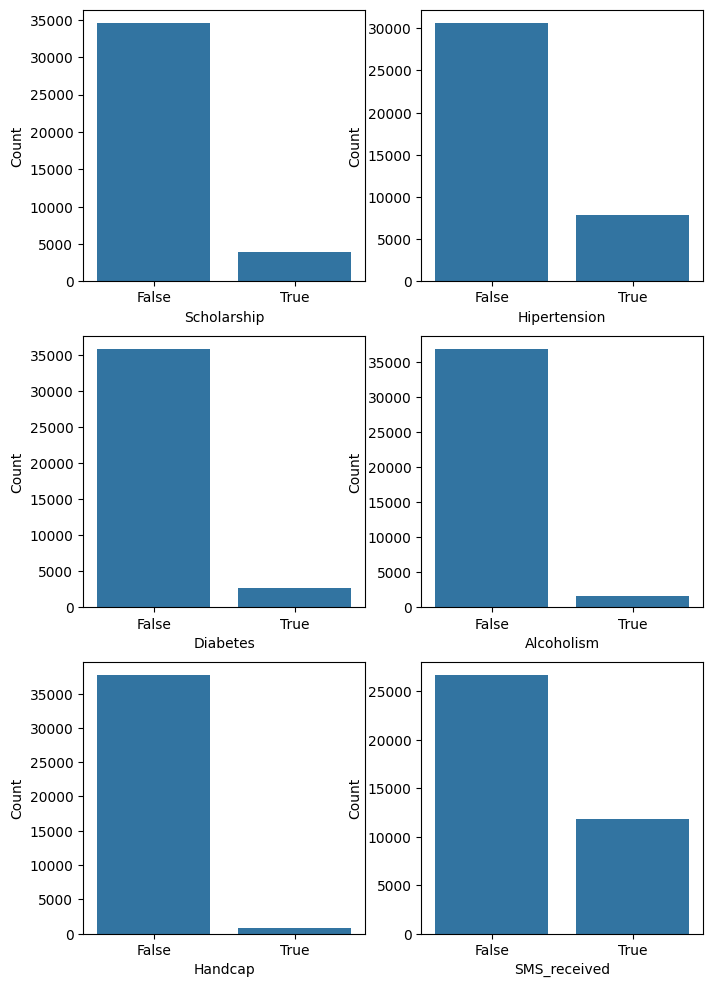

In [16]:
plt.figure(figsize=(8,12))

plt.subplot(3,2,1)
sns.countplot(x='Scholarship',data=df)
plt.xlabel('Scholarship')
plt.ylabel('Count')

plt.subplot(3,2,2)
sns.countplot(x='Hipertension',data=df)
plt.xlabel('Hipertension')
plt.ylabel('Count')

plt.subplot(3,2,3)
sns.countplot(x='Diabetes',data=df)
plt.xlabel('Diabetes')
plt.ylabel('Count')

plt.subplot(3,2,4)
sns.countplot(x='Alcoholism',data=df)
plt.xlabel('Alcoholism')
plt.ylabel('Count')

plt.subplot(3,2,5)
sns.countplot(x='Handcap',data=df)
plt.xlabel('Handcap')
plt.ylabel('Count')

plt.subplot(3,2,6)
sns.countplot(x='SMS_received',data=df)
plt.xlabel('SMS_received')
plt.ylabel('Count')

In [17]:
df['z_score'] = stats.zscore(df['Age'])
outliers = df[(df['z_score'] > 3) | (df['z_score'] < -3)]
outliers

,Gender,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,Showed_up,...,S_day_date,S_day_of_week,A_year,A_month,A_day_date,A_day_of_week,Year_difference,month_difference,day_difference,z_score


In [18]:
df = df[(df['z_score'] <= 3) & (df['z_score'] >= -3)]

df.drop('z_score', axis=1, inplace=True)

In [19]:
df['Age_sqrt'] = np.sqrt(df['Age'])
df['Age_log'] = np.log(df['Age'])

In [20]:
df.drop(['Age_sqrt','Age_log'],axis=1)

,Gender,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,Showed_up,...,S_month,S_day_date,S_day_of_week,A_year,A_month,A_day_date,A_day_of_week,Year_difference,month_difference,day_difference
0,F,62,JARDIM DA PENHA,False,True,False,False,False,False,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
1,M,56,JARDIM DA PENHA,False,False,False,False,False,False,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
2,F,62,MATA DA PRAIA,False,False,False,False,False,False,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
3,F,8,PONTAL DE CAMBURI,False,False,False,False,False,False,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
4,F,56,JARDIM DA PENHA,False,True,True,False,False,False,True,...,April,29,Friday,2016,April,29,Friday,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38562,F,28,INHANGUETÁ,True,False,False,False,False,False,False,...,May,11,Wednesday,2016,May,13,Friday,0,0,2
38563,F,11,GRANDE VITÓRIA,False,False,False,False,False,False,False,...,May,13,Friday,2016,May,13,Friday,0,0,0
38564,F,21,INHANGUETÁ,False,False,False,False,False,False,True,...,May,17,Tuesday,2016,May,20,Friday,0,0,3
38565,F,14,DA PENHA,False,False,False,False,False,False,True,...,May,30,Monday,2016,May,30,Monday,0,0,0


In [21]:
neighbourhood_counts = df['Neighbourhood'].value_counts()
neighbourhoods_to_replace = neighbourhood_counts[neighbourhood_counts < 1000].index
df['Neighbourhood'] = df['Neighbourhood'].replace(neighbourhoods_to_replace, 'OTHER')

In [22]:
df['Neighbourhood'].value_counts().head(50)

,count
Neighbourhood,
OTHER,23812
RESISTÊNCIA,2757
MARIA ORTIZ,1786
JESUS DE NAZARETH,1661
ROMÃO,1427
SANTA MARTHA,1362
FORTE SÃO JOÃO,1281
TABUAZEIRO,1210
SANTO ANDRÉ,1162


In [23]:
df = df.apply(lambda col: col.astype('int64') if col.dtype == 'int32' else col)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38567 entries, 0 to 38566
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            38567 non-null  object 
 1   Age               38567 non-null  int64  
 2   Neighbourhood     38567 non-null  object 
 3   Scholarship       38567 non-null  bool   
 4   Hipertension      38567 non-null  bool   
 5   Diabetes          38566 non-null  object 
 6   Alcoholism        38566 non-null  object 
 7   Handcap           38566 non-null  object 
 8   SMS_received      38566 non-null  object 
 9   Showed_up         38566 non-null  object 
 10  S_year            38567 non-null  int64  
 11  S_month           38567 non-null  object 
 12  S_day_date        38567 non-null  int64  
 13  S_day_of_week     38567 non-null  object 
 14  A_year            38567 non-null  int64  
 15  A_month           38567 non-null  object 
 16  A_day_date        38567 non-null  int64 

In [25]:
df.shape

(38567, 23)

In [26]:
X = df.drop('Showed_up',axis=1)
y = df['Showed_up']


In [27]:
num_col = X.select_dtypes(include=('int64'))
num_col = num_col.drop(['S_year','A_year','S_day_date','A_day_date'],axis=1)
num_col

,Age,Year_difference,month_difference,day_difference
0,62,0,0,0
1,56,0,0,0
2,62,0,0,0
3,8,0,0,0
4,56,0,0,0
...,...,...,...,...
38562,28,0,0,2
38563,11,0,0,0
38564,21,0,0,3
38565,14,0,0,0


In [28]:
categorical_col = X.select_dtypes(include=('category'))
categorical_col

""
0
1
2
3
4
...
38562
38563
38564
38565


In [29]:
class CountBasedOrdinalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.order_mappings = {}

    def fit(self, X, y=None):
        # Calculate value counts for each column and create mappings
        for col in range(X.shape[1]):
            value_counts = pd.Series(X[:, col]).value_counts()
            self.order_mappings[col] = {category: rank for rank, (category, _) in enumerate(value_counts.sort_values(ascending=False).items(), start=1)}
        return self

    def transform(self, X):
        # Directly encode the columns based on the mappings
        X_transformed = X.copy()
        for col in range(X.shape[1]):
            X_transformed[:, col] = pd.Series(X[:, col]).map(self.order_mappings[col]).fillna(0).astype(int)
        return X_transformed


In [30]:
bool_col = X.select_dtypes(include=('bool'))
bool_col

,Scholarship,Hipertension
0,False,True
1,False,False
2,False,False
3,False,False
4,False,True
...,...,...
38562,True,False
38563,False,False
38564,False,False
38565,False,False


In [31]:
obj_col = X.select_dtypes(include=('object'))
obj_col

,Gender,Neighbourhood,Diabetes,Alcoholism,Handcap,SMS_received,S_month,S_day_of_week,A_month,A_day_of_week
0,F,OTHER,False,False,False,False,April,Friday,April,Friday
1,M,OTHER,False,False,False,False,April,Friday,April,Friday
2,F,OTHER,False,False,False,False,April,Friday,April,Friday
3,F,OTHER,False,False,False,False,April,Friday,April,Friday
4,F,OTHER,True,False,False,False,April,Friday,April,Friday
...,...,...,...,...,...,...,...,...,...,...
38562,F,OTHER,False,False,False,False,May,Wednesday,May,Friday
38563,F,OTHER,False,False,False,False,May,Friday,May,Friday
38564,F,OTHER,False,False,False,False,May,Tuesday,May,Friday
38565,F,OTHER,False,False,False,False,May,Monday,May,Monday


In [38]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [48]:
def convert_to_str(x):
  return x.astype(str)

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    (('count_encoder', CountBasedOrdinalEncoder()))
])

boolean_transformer = Pipeline(steps=[
    ('bool_to_str', FunctionTransformer(convert_to_str)),
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder())
])

object_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, num_col.columns),
        ('cat', categorical_transformer, categorical_col.columns),
        ('bool', boolean_transformer, bool_col.columns),
        ('obj', object_transformer, obj_col.columns)
    ]
)

In [40]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

log_reg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(sampling_strategy='not majority',random_state=42)),
    ('classifier', LogisticRegression(class_weight='balanced',random_state=42))
])

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(sampling_strategy='not majority',random_state=42)),
    ('classifier', RandomForestClassifier(class_weight='balanced',random_state=42))
])

xgboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(scale_pos_weight=scale_pos_weight,random_state=42))
])

dec_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(sampling_strategy='not majority',random_state=42)),
    ('classifier', DecisionTreeClassifier(class_weight='balanced',random_state=42))
])

knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(sampling_strategy='not majority',random_state=42)),
    ('classifier', KNeighborsClassifier(weights='uniform'))
])

ada_boost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',random_state=42), n_estimators=100))
])

models = [log_reg_model,random_forest_model,xgboost_model,dec_tree_model,knn_model,ada_boost_model]

In [ ]:
# Handle missing values in y
y = y.fillna(y.mode()[0])

# Handle missing values in X
for col in X.columns:
    if X[col].dtype in ['int64', 'float64']:
        X[col] = X[col].fillna(X[col].mean())
    else:
        X[col] = X[col].fillna(X[col].mode()[0]).infer_objects(copy=False)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [42]:
for model in models:
    model.fit(X_train,y_train_encoded)
    y_pred = model.predict(X_train)
    class_report = classification_report(y_train_encoded, y_pred)
    model_name = type(model.named_steps['classifier']).__name__
    print(f'{model_name} report:')
    print(class_report)
    print('\n')

LogisticRegression report:
              precision    recall  f1-score   support

           0       0.33      0.56      0.42      6372
           1       0.86      0.70      0.77     24481

    accuracy                           0.68     30853
   macro avg       0.60      0.63      0.60     30853
weighted avg       0.75      0.68      0.70     30853



RandomForestClassifier report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      6372
           1       0.98      0.98      0.98     24481

    accuracy                           0.97     30853
   macro avg       0.96      0.95      0.95     30853
weighted avg       0.97      0.97      0.97     30853



XGBClassifier report:
              precision    recall  f1-score   support

           0       0.40      0.87      0.54      6372
           1       0.95      0.65      0.77     24481

    accuracy                           0.70     30853
   macro avg       0.67      0.76      0.66 

In [43]:
for model in models:
    y_pred = model.predict(X_test)
    class_report = classification_report(y_test_encoded, y_pred)
    model_name = type(model.named_steps['classifier']).__name__
    print(f'{model_name} report:')
    print(class_report)
    print('\n')

LogisticRegression report:
              precision    recall  f1-score   support

           0       0.33      0.57      0.42      1593
           1       0.86      0.70      0.77      6121

    accuracy                           0.67      7714
   macro avg       0.60      0.63      0.59      7714
weighted avg       0.75      0.67      0.70      7714



RandomForestClassifier report:
              precision    recall  f1-score   support

           0       0.36      0.34      0.35      1593
           1       0.83      0.84      0.83      6121

    accuracy                           0.74      7714
   macro avg       0.59      0.59      0.59      7714
weighted avg       0.73      0.74      0.73      7714



XGBClassifier report:
              precision    recall  f1-score   support

           0       0.32      0.73      0.45      1593
           1       0.89      0.60      0.72      6121

    accuracy                           0.63      7714
   macro avg       0.61      0.66      0.58 

PicklingError: Can't pickle <function <lambda> at 0x7b2192917ce0>: attribute lookup <lambda> on __main__ failed